<a href="https://colab.research.google.com/github/rtbn12/dap-2024/blob/main/les05/%D0%9B%D0%B0%D0%B1%D0%A0%D0%B0%D0%B1_5_%D0%A1%D0%BE%D0%BB%D0%BE%D0%B4%D0%BE%D0%B2_12002408.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
БЕЛГОРОДСКИЙ ГОСУДАРСТВЕННЫЙ НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ» (НИУ «БелГУ») ИНСТИТУТ ИНЖЕНЕРНЫХ И ЦИФРОВЫХ ТЕХНОЛОГИЙ Кафедра информационных и робототехнических систем

Отчет по лабораторной работе № 5 Тема работы: Визуализация данных

«Анализ данных на Python»

студента очного отделения 3 курса группы 12002408

Солодова Егора Николаевича

Проверил: ассистент Пузырёв Никита Сергеевич

БЕЛГОРОД 2026

In [20]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")

frame = pd.read_csv("https://raw.githubusercontent.com/chebotarevsa/dap-2024/refs/heads/main/les04/data/titanic.csv", index_col='PassengerId')
print(frame.shape)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Numpy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0
(891, 11)


**Задача 1**

Постройте два линейных графика функции y = 2/x + 3

 на одной оси координат, первый для диапазона x=[-10;0], а второй для x=[0;7].
 Графики должны быть помещены на оси с пределами xlim(-10, 10) и ylim(-10, 10), иметь подписи к осям, легенду и заголовок.
Первый график должен быть красного цвета и нарисован штрихпунктирной линией
Второй график должен иметь цвет (1.0,0.2,0.3) и нарисован сплошной линией

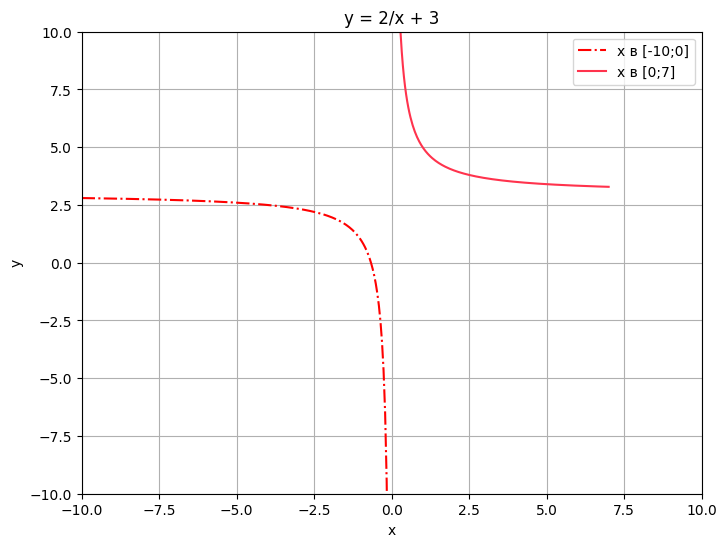

In [ ]:
x1 = np.linspace(-10, -0.01, 200)
x2 = np.linspace(0.01, 7, 200)

y1 = 2 / x1 + 3
y2 = 2 / x2 + 3

plt.figure(figsize=(8, 6))
plt.plot(x1, y1, 'r-.', label='x в [-10;0]')
plt.plot(x2, y2, color=(1.0, 0.2, 0.3), label='x в [0;7]')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.xlabel('x')
plt.ylabel('y')
plt.title('y = 2/x + 3')
plt.legend()
plt.grid()
plt.show()

**Задача 2**

Постройте диаграмму рассеяния для набора данных titanic (файл ./data/titanic.csv).

По оси X - возврат пассажира (Age)
По оси Y - стоимость билета (Fare)
Для выживших пассажиров используется маркер зеленый круг (Survived)
Для не выживших пассажиров используется маркер красный крест (Survived)
График должен подписи к осям и легенду и заголовок
Данные для которых не указан возврат или стоимость билета должны быть исключены

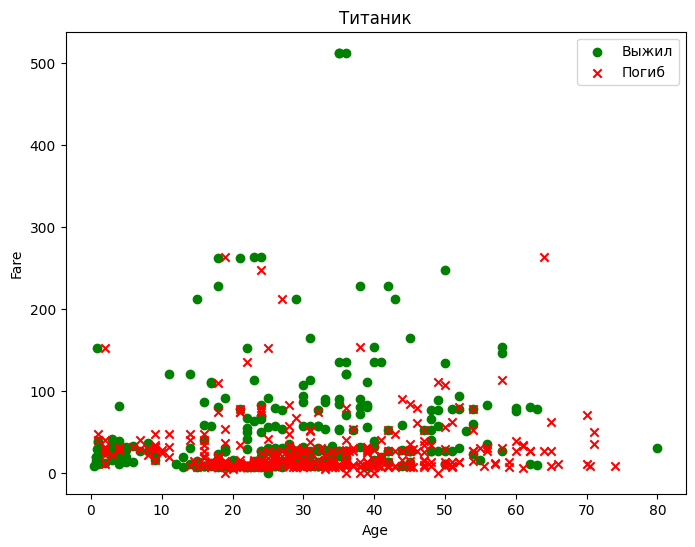

In [21]:
d = frame.dropna(subset=['Age', 'Fare'])

plt.figure(figsize=(8, 6))
plt.scatter(d[d['Survived'] == 1]['Age'], d[d['Survived'] == 1]['Fare'],
            c='green', marker='o', label='Выжил')
plt.scatter(d[d['Survived'] == 0]['Age'], d[d['Survived'] == 0]['Fare'],
            c='red', marker='x', label='Погиб')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Титаник')
plt.legend()
plt.show()

**Задача 3**

Для первоначального анализа данных часто используются диаграммы рассеяния для всех признаков из набора данных. Это позволяет визуально увидеть зависимости между признаками и выбросы. Для набора данных iris постройте на одном холсте 16 диаграмм рассеяния показывающих зависимости между всеми признаками набора ('sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)')

Холст должен содержать 16 графиков на отдельных осях (см. иллюстрацию к статье в Википедия)
Цвет маркеров должен зависеть от вида ирисов (iris.target)
Графики должны иметь подписи к осям, легенду и общий заголовок

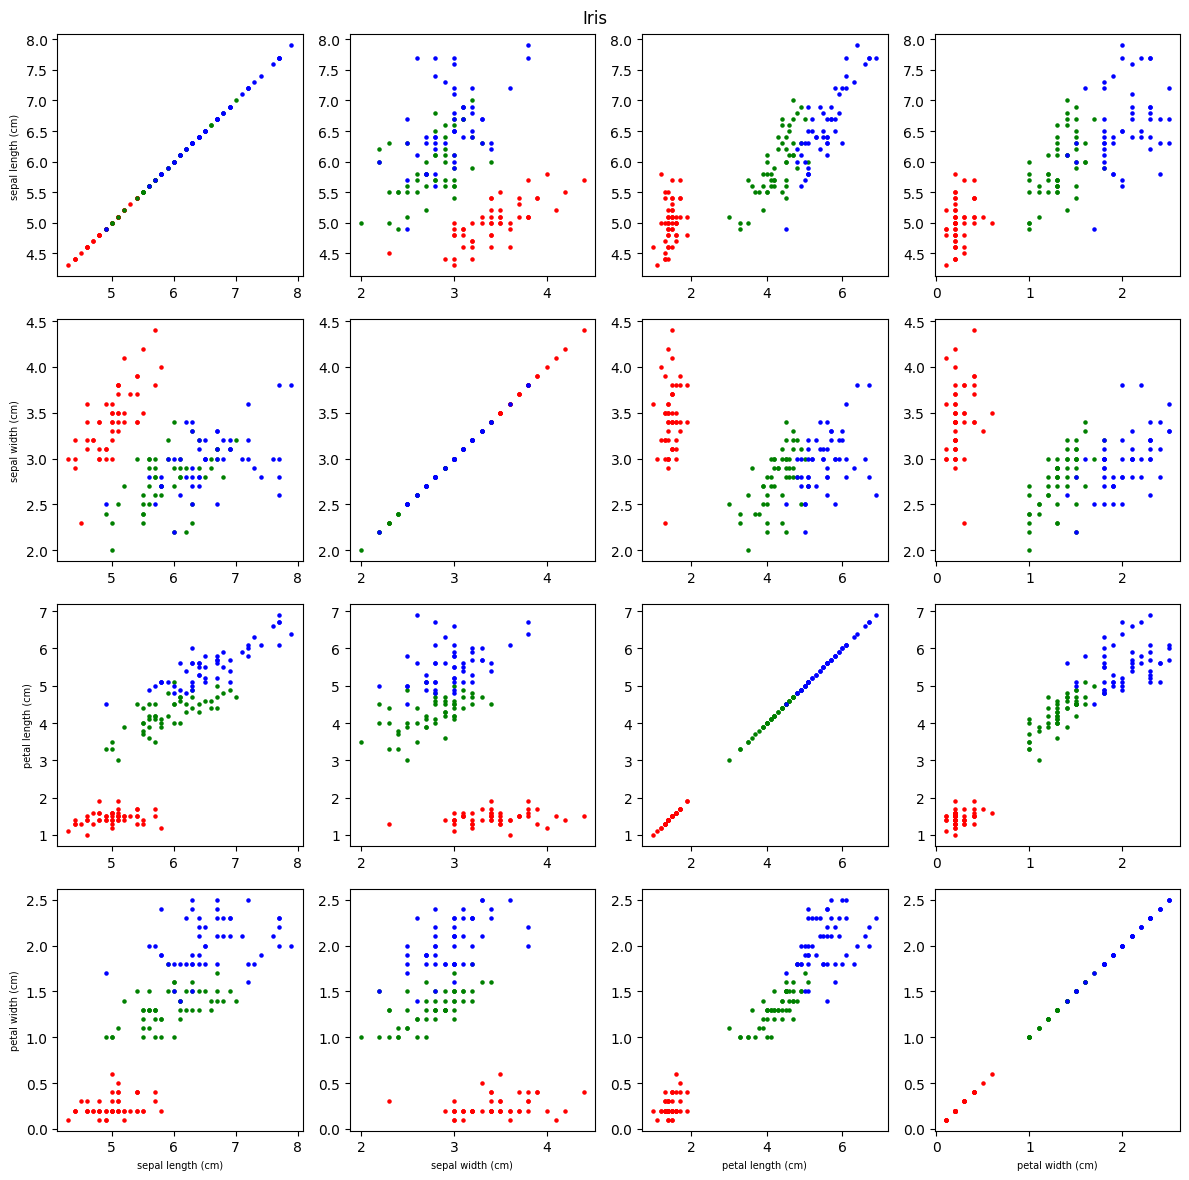

In [22]:
from sklearn.datasets import load_iris
iris = load_iris()

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
colors = ['red', 'green', 'blue']

for i in range(4):
    for j in range(4):
        for k in range(3):
            axes[i, j].scatter(iris.data[iris.target == k, j],
                               iris.data[iris.target == k, i],
                               c=colors[k], s=5)
        if i == 3:
            axes[i, j].set_xlabel(iris.feature_names[j], fontsize=7)
        if j == 0:
            axes[i, j].set_ylabel(iris.feature_names[i], fontsize=7)

fig.suptitle('Iris')
plt.tight_layout()
plt.show()

**Задача 4**

Постройте на одном холсте и разный осях следующие распределения для набора данных titanic (./data/titanic.csv):

Постройте гистограмму распределения пассажиров по возрасту (Age). Интервал 5 лет.
Постройте гистограмму распределения пассажиров женского пола по стоимости билетов (Fare). Подберите удобный интервал
График должен иметь подписи к осям, легенду и заголовок
Данные для которых не указан возраст или стоимость билета должны быть исключены

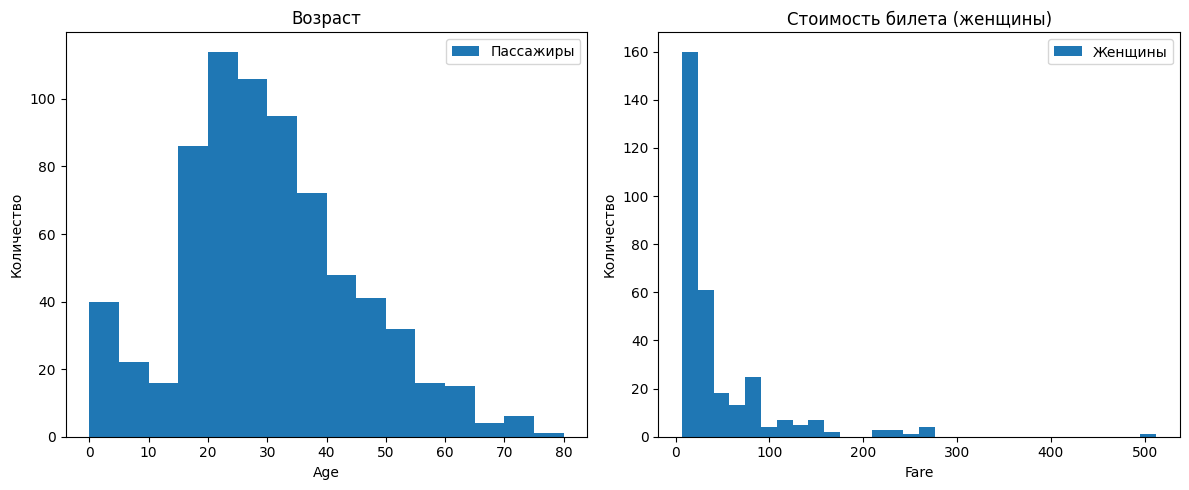

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(frame['Age'].dropna(), bins=range(0, 85, 5))
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Количество')
axes[0].set_title('Возраст')
axes[0].legend(['Пассажиры'])

axes[1].hist(frame[frame['Sex'] == 'female']['Fare'].dropna(), bins=30)
axes[1].set_xlabel('Fare')
axes[1].set_ylabel('Количество')
axes[1].set_title('Стоимость билета (женщины)')
axes[1].legend(['Женщины'])

plt.tight_layout()
plt.show()

**Задача 5**

Для набора данных для набора данных titanic (./data/titanic.csv) постройте следующую столбчатую диаграмму:

Диаграмма должна быть вертикальной
По оси X - класс каюты пассажира (Pclass)
По оси Y - средняя стоимость за проезд для данного класса (Fare)
График должен иметь подписи к осям, легенду и заголовок

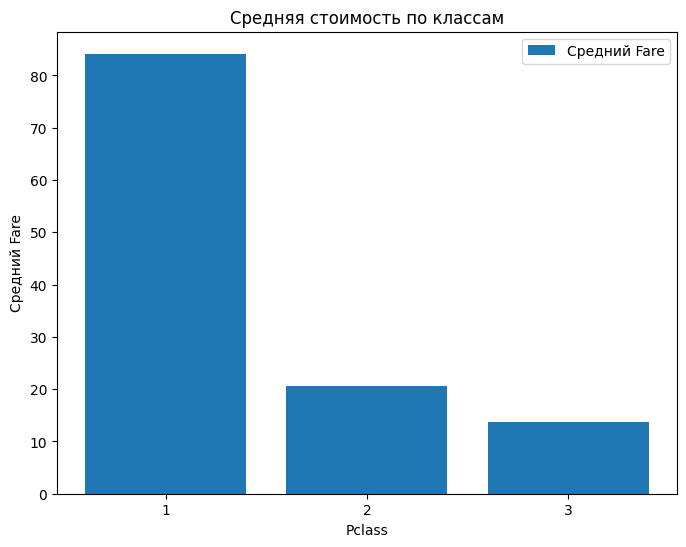

In [24]:
avg = frame.groupby('Pclass')['Fare'].mean()

plt.figure(figsize=(8, 6))
plt.bar(avg.index.astype(str), avg.values)
plt.xlabel('Pclass')
plt.ylabel('Средний Fare')
plt.title('Средняя стоимость по классам')
plt.legend(['Средний Fare'])
plt.show()

**Задача 6**

Для набора данных для набора данных titanic (./data/titanic.csv) постройте следующую столбчатую диаграмму c накоплением:

Диаграмма должна быть вертикальной
По оси X - класс каюты пассажира (Pclass)
По оси Y - количество пассажиров с разбивкой по полу (Sex)
График должен иметь подписи к осям, легенду и заголовок

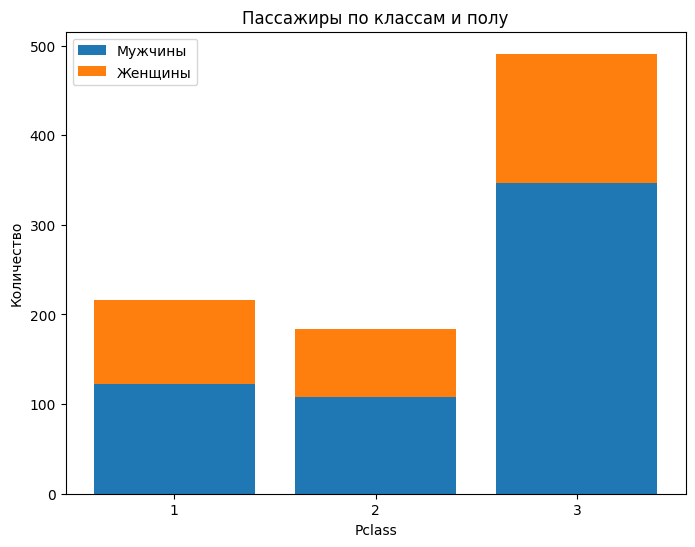

In [25]:
counts = frame.groupby(['Pclass', 'Sex']).size().unstack(fill_value=0)

plt.figure(figsize=(8, 6))
plt.bar(counts.index.astype(str), counts['male'], label='Мужчины')
plt.bar(counts.index.astype(str), counts['female'], bottom=counts['male'], label='Женщины')
plt.xlabel('Pclass')
plt.ylabel('Количество')
plt.title('Пассажиры по классам и полу')
plt.legend()
plt.show()

**Задача 7**

Для набора данных iris постройте круговую диаграмму

Диаграмма должна иметь 3 сектора отражающих долю ирисов данного вида в наборе
Сектор с максимальной долей долен быть выдвинут
График должен иметь подписи к осям, легенду и заголовок

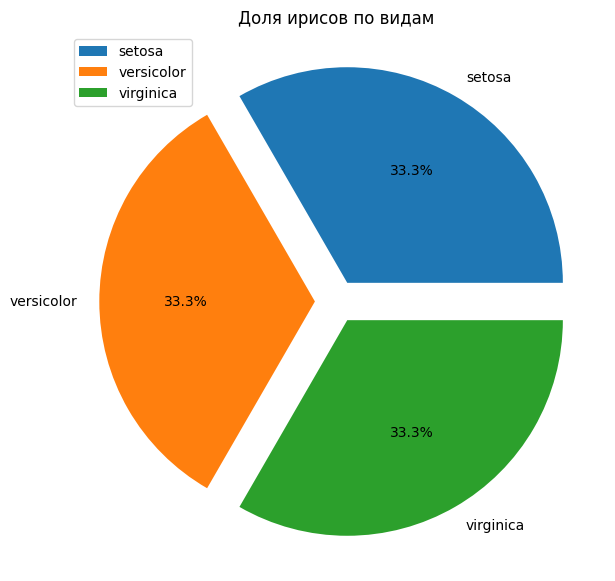

In [16]:
counts = np.bincount(iris.target)
explode = [0.1 if c == counts.max() else 0 for c in counts]

plt.figure(figsize=(7, 7))
plt.pie(counts, labels=iris.target_names, autopct='%1.1f%%', explode=explode)
plt.title('Доля ирисов по видам')
plt.legend(iris.target_names)
plt.show()

**Задача 8**

Использую библиотеку Seaborn постройте гистограмму для возраста пассажиров "Титаника"

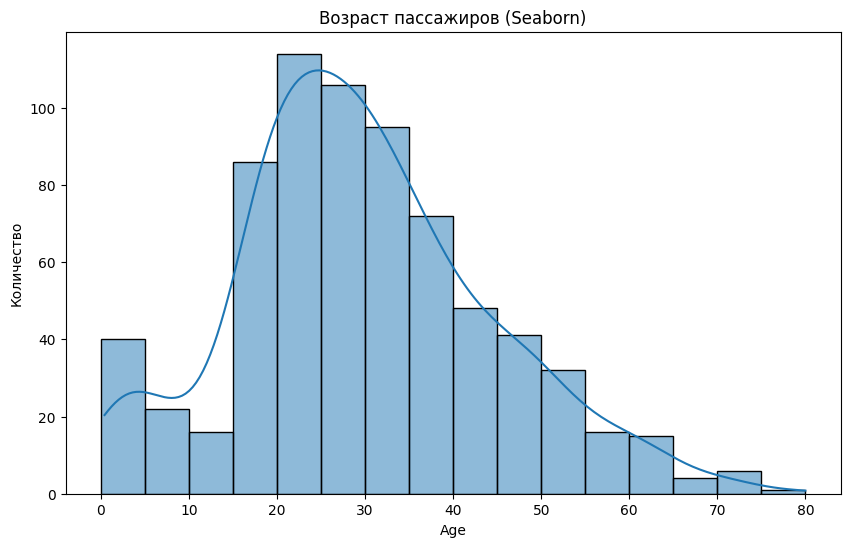

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(data=frame, x='Age', bins=range(0, 85, 5), kde=True)
plt.xlabel('Age')
plt.ylabel('Количество')
plt.title('Возраст пассажиров (Seaborn)')
plt.show()

**Вывод:** а ходе выполнения лабораторной работы была проведена визуализация данных в виде построения графиков, с применением юиюлиотеки "matplotlib".

**Ответы на контрольные вопросы**

**Для чего используется диаграмма рассеяния?**
Диаграмма рассеяния используется для отображения зависимости между двумя величинами и поиска выбросов: каждая точка — наблюдение с координатами двух признаков.

**Что такое гистограмма, чем он отличается от столбчатой диаграммы?**
Гистограмма — это график распределения частот: по одной оси интервалы значений, по другой количество попаданий. Столбчатая диаграмма сравнивает отдельные категории, а не диапазоны, и столбцы не соприкасаются.

**Как задать цвет линии в линейном графике Matplotlib?**
Цвет линии задаётся параметром color: именем ('red', 'blue'), коротким кодом ('r', 'g', 'b'), hex-кодом ('#FFDD44'), кортежем RGB (1.0, 0.2, 0.3) или оттенком серого ('0.75').

**Чем класс plt.Figure отличается от объекта plt.Axes?**
plt.Figure — это весь холст-контейнер. plt.Axes — отдельная система координат внутри холста с осями и графиками. На одном Figure может быть несколько Axes.

**Matplotlib не позволяет управлять типом маркера scatter графика. Да или нет?**
Нет, неверно. Matplotlib позволяет задать тип маркера через параметр marker у scatter и plot: 'o', 'x', 'p', '^' и другие.

**Matplotlib единственная библиотека для построения графиков в Python. Да или нет?**
Нет, неверно. Есть Seaborn, Plotly, Bokeh, Altair и другие библиотеки визуализации.

**Matplotlib не позволяет сохранить график в виде файла, нужно делать скриншот?**
Нет, неверно. График сохраняется методом savefig, например fig.savefig('plot.png').

**В наборе данных iris представлены 4 вида ирисов. Да или нет?**
Нет, неверно. В наборе iris три вида ирисов: setosa, versicolor, virginica.

**Для всех пассажиров "Титаника" указан возраст. Да или нет?**
Нет, неверно. В Titanic у части пассажиров возраст отсутствует, поэтому перед анализом нужно удалять пропуски через dropna

**Как на одном холсте может располагаться не более 16 диаграмм, это обусловлено тем что размер диаграммы нельзя изменить и более мелкие графики попросту не будут видны.**
Нет, неверно. На одном холсте можно разместить сколько угодно графиков, размер холста задаётся через figsize, а сетка — через subplots. Ограничение в 16 ничем не обусловлено